# KPTracer tree plotting with metastasis site labels

This notebook lets you choose any tree from `data/KPTracer-Data/trees`, map the leaf cell barcodes to KPTracer metadata, and plot the tree with leaves colored by anatomical/metastasis site.

Change `TREE_NAME`, `ANNOTATION_COLUMN`, or `USE_SITE_LABELS` in the configuration cell to inspect any tree.

In [20]:
import os
import glob
from collections import defaultdict

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from newick import read

DATA_ROOT = os.path.join('../data', 'KPTracer-Data')
TREE_DIR = os.path.join(DATA_ROOT, 'trees')
META_PATH = os.path.join(DATA_ROOT, 'KPTracer_meta.csv')

meta = pd.read_csv(META_PATH, index_col=0)
meta.index = meta.index.astype(str)

available_trees = sorted(glob.glob(os.path.join(TREE_DIR, '*_tree.nwk')))
available_tree_names = [os.path.basename(path) for path in available_trees]

print(f'Loaded metadata with {len(meta)} cells')
print(f'Found {len(available_tree_names)} tree files')
print('\nSample trees:')
for tree_name in available_tree_names[:20]:
    print(' -', tree_name)

print('\nAvailable annotation columns:')
for col in ['Tumor', 'SubTumor', 'MetFamily', 'genotype', 'Lane']:
    print(' -', col)

Loaded metadata with 106684 cells
Found 86 tree files

Sample trees:
 - 3430_NT_T1_tree.nwk
 - 3430_NT_T2_tree.nwk
 - 3432_NT_T1_tree.nwk
 - 3432_NT_T2_tree.nwk
 - 3433_NT_T2_tree.nwk
 - 3434_NT_T1_tree.nwk
 - 3434_NT_T2_tree.nwk
 - 3434_NT_T3_tree.nwk
 - 3435_NT_T1_tree.nwk
 - 3435_NT_T3_tree.nwk
 - 3435_NT_T4_tree.nwk
 - 3435_NT_T6_tree.nwk
 - 3451_Lkb1_T1_tree.nwk
 - 3451_Lkb1_T2_tree.nwk
 - 3451_Lkb1_T3_tree.nwk
 - 3454_Lkb1_All_tree.nwk
 - 3454_Lkb1_T1_tree.nwk
 - 3454_Lkb1_T2_tree.nwk
 - 3454_Lkb1_T3_tree.nwk
 - 3457_Apc_T1_Fam_tree.nwk

Available annotation columns:
 - Tumor
 - SubTumor
 - MetFamily
 - genotype
 - Lane


In [21]:
# Configuration: change this to plot a different tree or annotation style.
TREE_NAME = '3513_NT_T1_Fam_tree.nwk'
ANNOTATION_COLUMN = 'SubTumor'
USE_SITE_LABELS = True
COLOR_PALETTE = 'tab10'

TREE_PATH = os.path.join(TREE_DIR, TREE_NAME)

if TREE_PATH not in available_trees:
    raise FileNotFoundError(f'Tree file not found: {TREE_PATH}')

print('Plotting tree:', TREE_NAME)
print('Annotation column:', ANNOTATION_COLUMN)
print('Use site labels:', USE_SITE_LABELS)

Plotting tree: 3513_NT_T1_Fam_tree.nwk
Annotation column: SubTumor
Use site labels: True



Leaf annotation counts:
T1    969
N1    243
K1     15
Name: count, dtype: int64


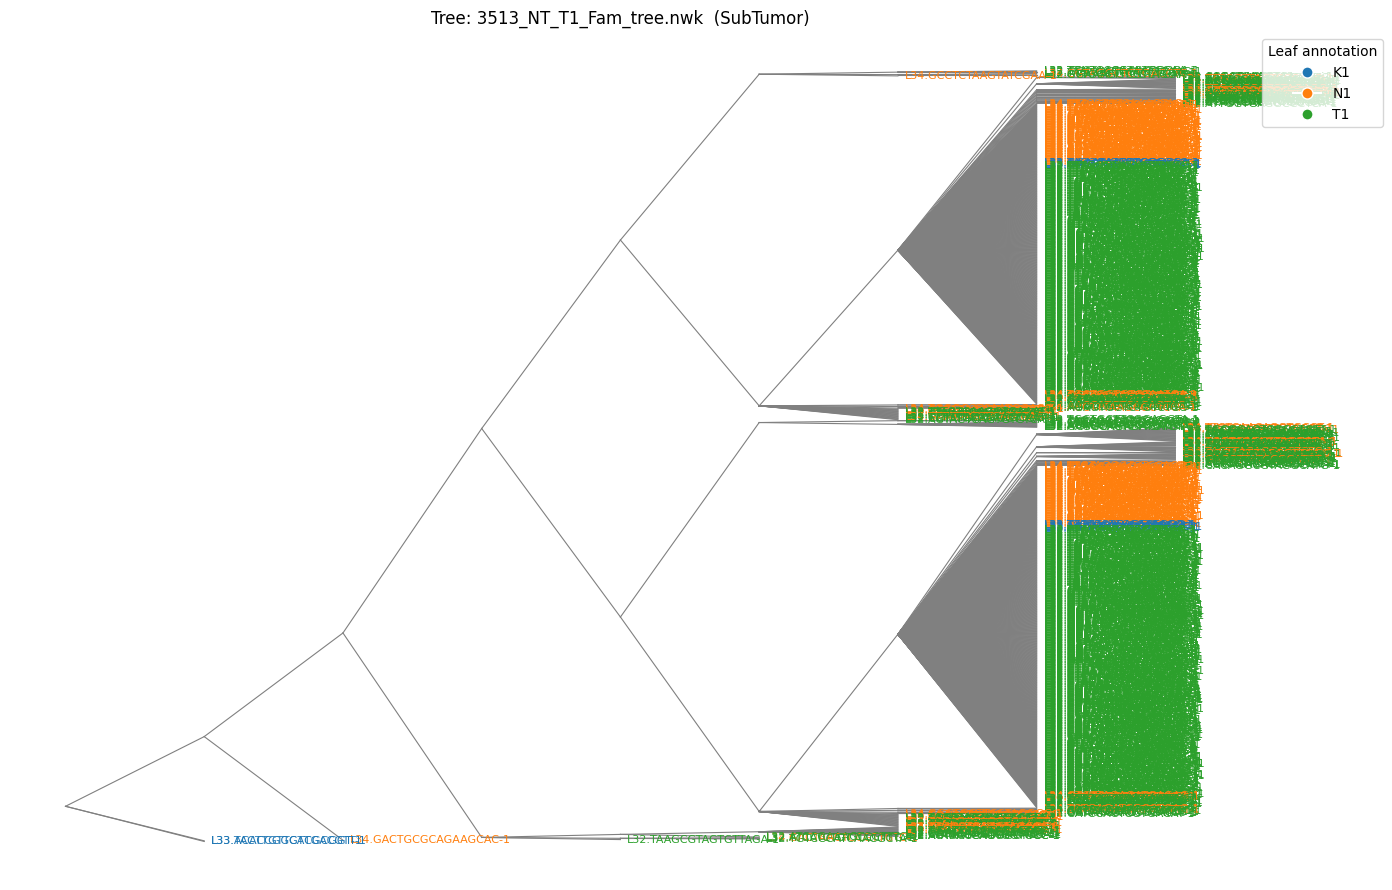

In [22]:
import numpy as np
from matplotlib.lines import Line2D

KNOWN_SITES = {
    'Rib': 'Rib',
    'S': 'Soft tissue',
    'N': 'Lymph',
    'K': 'Kidney',
    'Liv': 'Liver',
    'Spl': 'Spleen',
    'DN': 'Draining lymph',
    'PF': 'Pleural fluid',
    'B': 'Blood',
    'Normal': 'Normal',
}


def normalize_subtumor_label(value):
    if pd.isna(value):
        return 'Unknown'
    s = str(value)
    if s == '':
        return 'Unknown'
    parts = s.split('_')
    while len(parts) > 1 and (parts[-1] in {'a', 'b'} or parts[-1].isdigit()):
        parts = parts[:-1]
    last = parts[-1]
    if last in KNOWN_SITES:
        return KNOWN_SITES[last]
    if last.startswith('T') and len(parts) >= 3:
        return last
    if len(parts) >= 2 and parts[-2] in KNOWN_SITES:
        return KNOWN_SITES[parts[-2]]
    if 'Normal' in s:
        return 'Normal'
    return last


def build_leaf_annotations(tree, annotation_column='SubTumor', use_site_labels=True):
    annotation = {}
    missing = 0
    for leaf in tree.walk():
        if not leaf.descendants:
            name = str(leaf.name)
            if name not in meta.index:
                annotation[name] = 'Unknown'
                missing += 1
                continue
            value = meta.loc[name, annotation_column]
            if use_site_labels:
                annotation[name] = normalize_subtumor_label(value)
            else:
                annotation[name] = str(value) if pd.notna(value) else 'Unknown'
    if missing:
        print(f'Warning: {missing} leaf names were not found in metadata and will be labeled Unknown')
    return annotation


def lineage_tree_layout(node, depth=0, leaf_y=None, positions=None, parent=None, ids=None):
    if positions is None:
        positions = {}
    if ids is None:
        ids = {}

    node_id = ids.get(node)
    if node_id is None:
        node_id = node.name if node.name else f'inner_{len(ids)}'
        ids[node] = node_id
    child_ids = []
    for child in node.descendants:
        child_id = lineage_tree_layout(child, depth + 1, leaf_y, positions, node_id, ids)
        child_ids.append(child_id)

    if not child_ids:
        if leaf_y is None:
            raise ValueError('leaf_y generator must be provided')
        positions[node_id] = {'x': depth, 'y': next(leaf_y), 'node': node}
    else:
        ys = [positions[child_id]['y'] for child_id in child_ids]
        positions[node_id] = {'x': depth, 'y': np.mean(ys), 'node': node}

    return node_id


def plot_tree(tree, leaf_annotation, title=None, figsize=(14, 9), label_fontsize=8):
    root = tree
    if root is None:
        raise ValueError('Parsed tree is empty')

    leaf_count = len([n for n in root.walk() if not n.descendants])
    leaf_y = iter(np.arange(leaf_count)[::-1])
    positions = {}
    lineage_tree_layout(root, depth=0, leaf_y=leaf_y, positions=positions)

    fig, ax = plt.subplots(figsize=figsize)

    for node_id, info in positions.items():
        node = info['node']
        if node.descendants:
            for child in node.descendants:
                child_id = None
                for key, child_info in positions.items():
                    if child_info['node'] is child:
                        child_id = key
                        break
                if child_id is None:
                    continue
                x0, y0 = positions[node_id]['x'], positions[node_id]['y']
                x1, y1 = positions[child_id]['x'], positions[child_id]['y']
                ax.plot([x0, x1], [y0, y1], color='gray', linewidth=0.8)

    leaf_nodes = [nid for nid, info in positions.items() if not info['node'].descendants]
    site_names = sorted({leaf_annotation.get(info['node'].name, 'Unknown') for nid, info in positions.items() if not info['node'].descendants})
    palette = sns.color_palette(COLOR_PALETTE, n_colors=max(2, len(site_names)))
    color_map = {site: palette[i % len(palette)] for i, site in enumerate(site_names)}

    for nid in leaf_nodes:
        info = positions[nid]
        leaf_name = info['node'].name
        site = leaf_annotation.get(leaf_name, 'Unknown')
        ax.text(info['x'] + 0.05, info['y'], leaf_name, fontsize=label_fontsize, color=color_map[site], verticalalignment='center')

    legend_elements = [Line2D([0], [0], marker='o', color='w', label=site, markerfacecolor=color_map[site], markersize=8) for site in site_names]
    ax.legend(handles=legend_elements, title='Leaf annotation', bbox_to_anchor=(1.02, 1), loc='upper left')
    ax.axis('off')
    ax.set_title(title or f'Tree: {TREE_NAME}  ({ANNOTATION_COLUMN})')
    plt.tight_layout()
    return fig


tree = read(TREE_PATH)[0]
leaf_annotation = build_leaf_annotations(tree, annotation_column=ANNOTATION_COLUMN, use_site_labels=USE_SITE_LABELS)

site_counts = pd.Series(list(leaf_annotation.values())).value_counts()
print('\nLeaf annotation counts:')
print(site_counts)

fig = plot_tree(tree, leaf_annotation)
plt.show()

Using tree file: 3513_NT_T1_Fam_tree.nwk
Reading matching character matrix for tree file
Running ConvexML on 1227 leaf sequences...


/var/folders/nz/jn74t1g51q10qyclfkkr8cgm0000gq/T/ipykernel_37340/534447121.py:13: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  char_mat = char_mat.applymap(lambda x: int(x) if pd.notna(x) else -1)
(CVXPY) Jul 03 12:57:55 AM: Your problem has 2454 variables, 3680 constraints, and 0 parameters.
(CVXPY) Jul 03 12:57:55 AM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Jul 03 12:57:55 AM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) Jul 03 12:57:55 AM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
(CVXPY) Jul 03 12:57:55 AM: Your problem is compiled with the CPP canonicalization backend.
(CVXPY) Jul 03 12:57:55 AM: Compiling problem (target solver=ECOS).
(CVXPY) Jul 03 12:57:55 AM: Reduction chain: FlipObjective -> Dcp2Cone -> CvxAttr2Constr -> ConeMatrixStuffing -> ECOS
(CVXPY) Jul 03 12:57:55 AM: Applying reducti

                                     CVXPY                                     
                                     v1.8.2                                    
-------------------------------------------------------------------------------
                                  Compilation                                  
-------------------------------------------------------------------------------
-------------------------------------------------------------------------------
                                Numerical solver                               
-------------------------------------------------------------------------------

ECOS 2.0.10 - (C) embotech GmbH, Zurich Switzerland, 2012-15. Web: www.embotech.com/ECOS

It     pcost       dcost      gap   pres   dres    k/t    mu     step   sigma     IR    |   BT
 0  +0.000e+00  -2.940e+03  +2e+04  7e-01  6e-01  1e+00  1e+00    ---    ---    0  0  - |  -  - 
 1  +4.408e+01  -2.576e+03  +2e+04  3e-01  6e-01  9e-01  9e-01  0.2007  4e-01

(CVXPY) Jul 03 12:57:56 AM: Finished problem compilation (took 2.132e-02 seconds).
(CVXPY) Jul 03 12:57:56 AM: Invoking solver SCS  to obtain a solution.


-------------------------------------------------------------------------------
                                Numerical solver                               
-------------------------------------------------------------------------------
------------------------------------------------------------------
	       SCS v3.2.11 - Splitting Conic Solver
	(c) Brendan O'Donoghue, Stanford University, 2012
------------------------------------------------------------------
problem:  variables n: 7364, constraints m: 18410
cones: 	  z: primal zero / dual free vars: 1227
	  l: linear vars: 2453
	  e: exp vars: 14730, dual exp vars: 0
settings: eps_abs: 1.0e-05, eps_rel: 1.0e-05, eps_infeas: 1.0e-07
	  alpha: 1.50, scale: 1.00e-01, adaptive_scale: 1
	  max_iters: 100000, normalize: 1, rho_x: 1.00e-06
	  acceleration_lookback: 10, acceleration_interval: 10
lin-sys:  sparse-direct-amd-qdldl
	  nnz(A): 22086, nnz(P): 0
------------------------------------------------------------------
 iter | pri re

(CVXPY) Jul 03 12:57:57 AM: Problem status: optimal
(CVXPY) Jul 03 12:57:57 AM: Optimal value: -4.691e+01
(CVXPY) Jul 03 12:57:57 AM: Compilation took 2.132e-02 seconds
(CVXPY) Jul 03 12:57:57 AM: Solver (including time spent in interface) took 1.364e+00 seconds


   750| 7.94e-05  5.02e-06  1.94e-05  4.69e+01  1.00e-01  1.22e+00 
   825| 4.69e-05  4.90e-06  9.77e-06  4.69e+01  1.00e-01  1.36e+00 
------------------------------------------------------------------
status:  solved
timings: total: 1.36e+00s = setup: 7.31e-03s + solve: 1.36e+00s
	 lin-sys: 2.50e-01s, cones: 1.05e+00s, accel: 8.64e-03s
------------------------------------------------------------------
objective = 46.914098
------------------------------------------------------------------
-------------------------------------------------------------------------------
                                    Summary                                    
-------------------------------------------------------------------------------

ConvexML branch-length estimation complete.
Branch length model: IIDExponentialMLE
Saved timed tree to ../data/KPTracer-Data/trees/3513_NT_T1_Fam_timed_tree.nwk


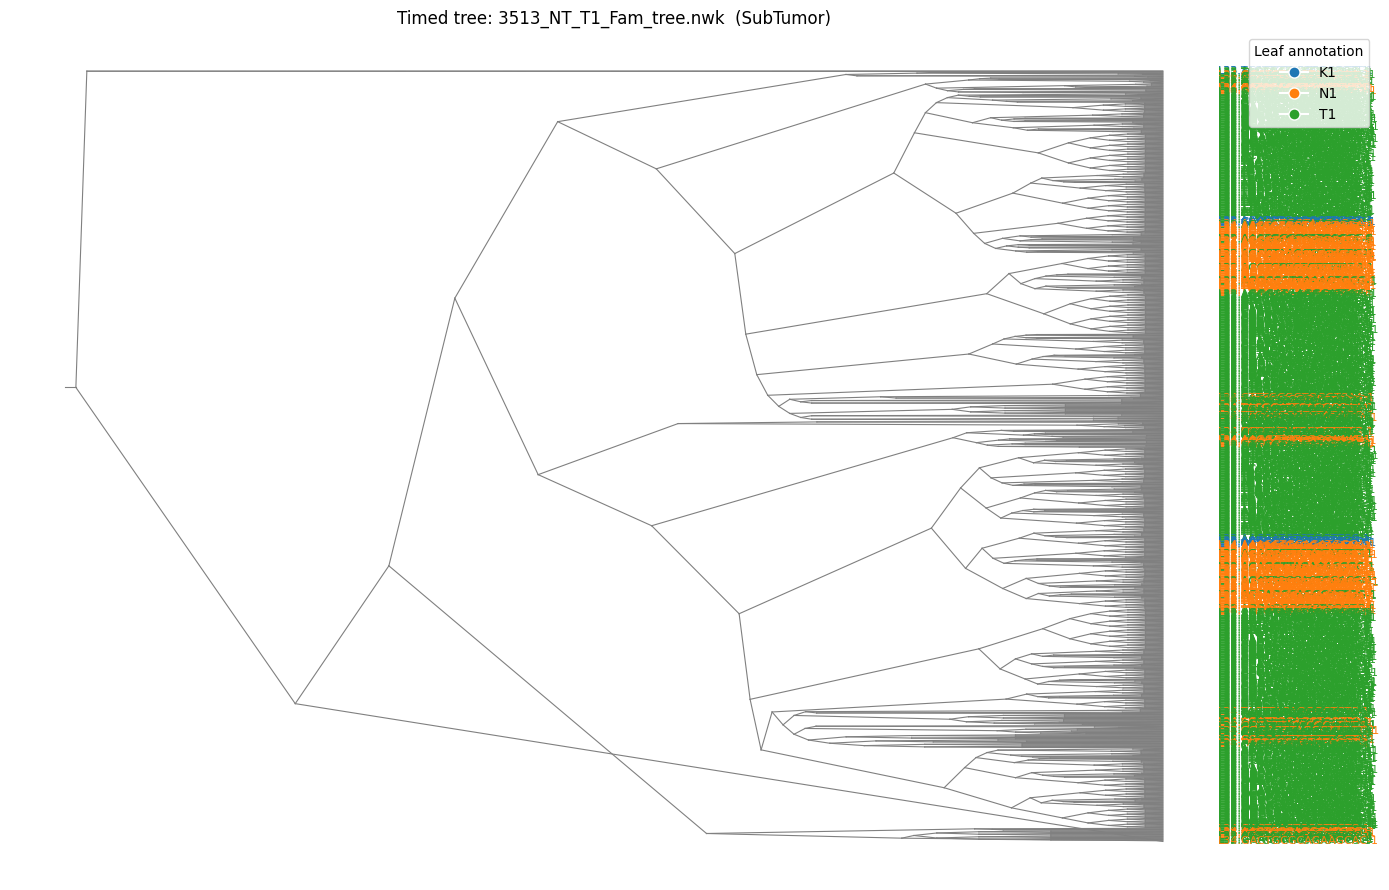

In [34]:
import convexml
from newick import loads


def read_character_matrix_for_tree(tree_filename):
    # TREE_NAME is the Newick tree file name. We derive the matching character matrix
    # file name by replacing the tree suffix with the expected matrix suffix.
    char_path = os.path.join(TREE_DIR, tree_filename.replace('_tree.nwk', '_character_matrix.txt'))
    if not os.path.exists(char_path):
        raise FileNotFoundError(f'Character matrix file not found for tree {tree_filename}: {char_path}')
    char_mat = pd.read_csv(char_path, sep='\t', index_col=0, dtype=str)
    char_mat = char_mat.replace('-', '-1')
    char_mat = char_mat.applymap(lambda x: int(x) if pd.notna(x) else -1)
    return char_mat


def build_convexml_leaf_sequences(tree, char_mat):
    leaf_names = [str(node.name) for node in tree.walk() if not node.descendants]
    missing = [name for name in leaf_names if name not in char_mat.index]
    if missing:
        raise KeyError(
            f'The following leaf names are missing from the character matrix and are required for ConvexML: {missing[:10]} ' \
            f'({len(missing)} missing total)')
    return {leaf: char_mat.loc[leaf].tolist() for leaf in leaf_names}


def timed_tree_layout(node, parent_x=0.0, leaf_y=None, positions=None, ids=None):
    if positions is None:
        positions = {}
    if ids is None:
        ids = {}

    node_id = ids.get(node)
    if node_id is None:
        node_id = node.name if node.name else f'inner_{len(ids)}'
        ids[node] = node_id

    current_x = parent_x + (float(node.length) if node.length is not None else 0.0)
    child_ids = []
    for child in node.descendants:
        child_id = timed_tree_layout(child, current_x, leaf_y, positions, ids)
        child_ids.append(child_id)

    if not child_ids:
        if leaf_y is None:
            raise ValueError('leaf_y generator must be provided')
        positions[node_id] = {'x': current_x, 'y': next(leaf_y), 'node': node}
    else:
        ys = [positions[child_id]['y'] for child_id in child_ids]
        positions[node_id] = {'x': current_x, 'y': np.mean(ys), 'node': node}

    return node_id


def plot_timed_tree(tree, leaf_annotation, title=None, figsize=(14, 9), label_fontsize=8):
    leaf_nodes = [node for node in tree.walk() if not node.descendants]
    leaf_count = len(leaf_nodes)
    leaf_y = iter(np.arange(leaf_count)[::-1])
    positions = {}
    timed_tree_layout(tree, parent_x=0.0, leaf_y=leaf_y, positions=positions)

    fig, ax = plt.subplots(figsize=figsize)
    for node_id, info in positions.items():
        node = info['node']
        if node.descendants:
            for child in node.descendants:
                child_id = next((key for key, child_info in positions.items() if child_info['node'] is child), None)
                if child_id is None:
                    continue
                x0, y0 = positions[node_id]['x'], positions[node_id]['y']
                x1, y1 = positions[child_id]['x'], positions[child_id]['y']
                ax.plot([x0, x1], [y0, y1], color='gray', linewidth=0.8)

    site_names = sorted({leaf_annotation.get(node.name, 'Unknown') for node in leaf_nodes})
    palette = sns.color_palette(COLOR_PALETTE, n_colors=max(2, len(site_names)))
    color_map = {site: palette[i % len(palette)] for i, site in enumerate(site_names)}

    for node in leaf_nodes:
        nid = next(key for key, info in positions.items() if info['node'] is node)
        info = positions[nid]
        leaf_name = node.name
        site = leaf_annotation.get(leaf_name, 'Unknown')
        ax.text(info['x'] + 0.05, info['y'], leaf_name, fontsize=label_fontsize, color=color_map[site], verticalalignment='center')

    legend_elements = [Line2D([0], [0], marker='o', color='w', label=site, markerfacecolor=color_map[site], markersize=8) for site in site_names]
    ax.legend(handles=legend_elements, title='Leaf annotation', bbox_to_anchor=(1.02, 1), loc='upper left')
    ax.axis('off')
    ax.set_title(title or f'Timed tree: {TREE_NAME}  ({ANNOTATION_COLUMN})')
    plt.tight_layout()
    return fig

print('Using tree file:', TREE_NAME)
print('Reading matching character matrix for tree file')
char_mat = read_character_matrix_for_tree(TREE_NAME)
leaf_sequences = build_convexml_leaf_sequences(tree, char_mat)

print('Running ConvexML on', len(leaf_sequences), 'leaf sequences...')
result = convexml.convexml(
    tree_newick=open(TREE_PATH).read().strip(),
    leaf_sequences=leaf_sequences,
    ancestral_state_reconstructor='conservative_maximum_parsimony',
    resolve_multifurcations_before_branch_length_estimation=True,
    recover_multifurcations_after_branch_length_estimation=False,
    minimum_branch_length=0.01,
    pseudo_mutations_per_edge=0.05,
    pseudo_non_mutations_per_edge=0.05,
    solver='ECOS',
    backup_solver='SCS',
    verbose=True,
)

print('\nConvexML branch-length estimation complete.')
print('Branch length model:', type(result['model']).__name__)

TIMED_TREE_NAME = TREE_NAME.replace('_tree.nwk', '_timed_tree.nwk')
TIMED_TREE_PATH = os.path.join(TREE_DIR, TIMED_TREE_NAME)
with open(TIMED_TREE_PATH, 'w') as f:
    f.write(result['tree_newick'] + '\n')
print('Saved timed tree to', TIMED_TREE_PATH)

# Plot the timed tree with the same leaf annotations.

plt.close('all')
timed_tree = loads(result['tree_newick'])[0]
fig = plot_timed_tree(timed_tree, leaf_annotation)
plt.show()

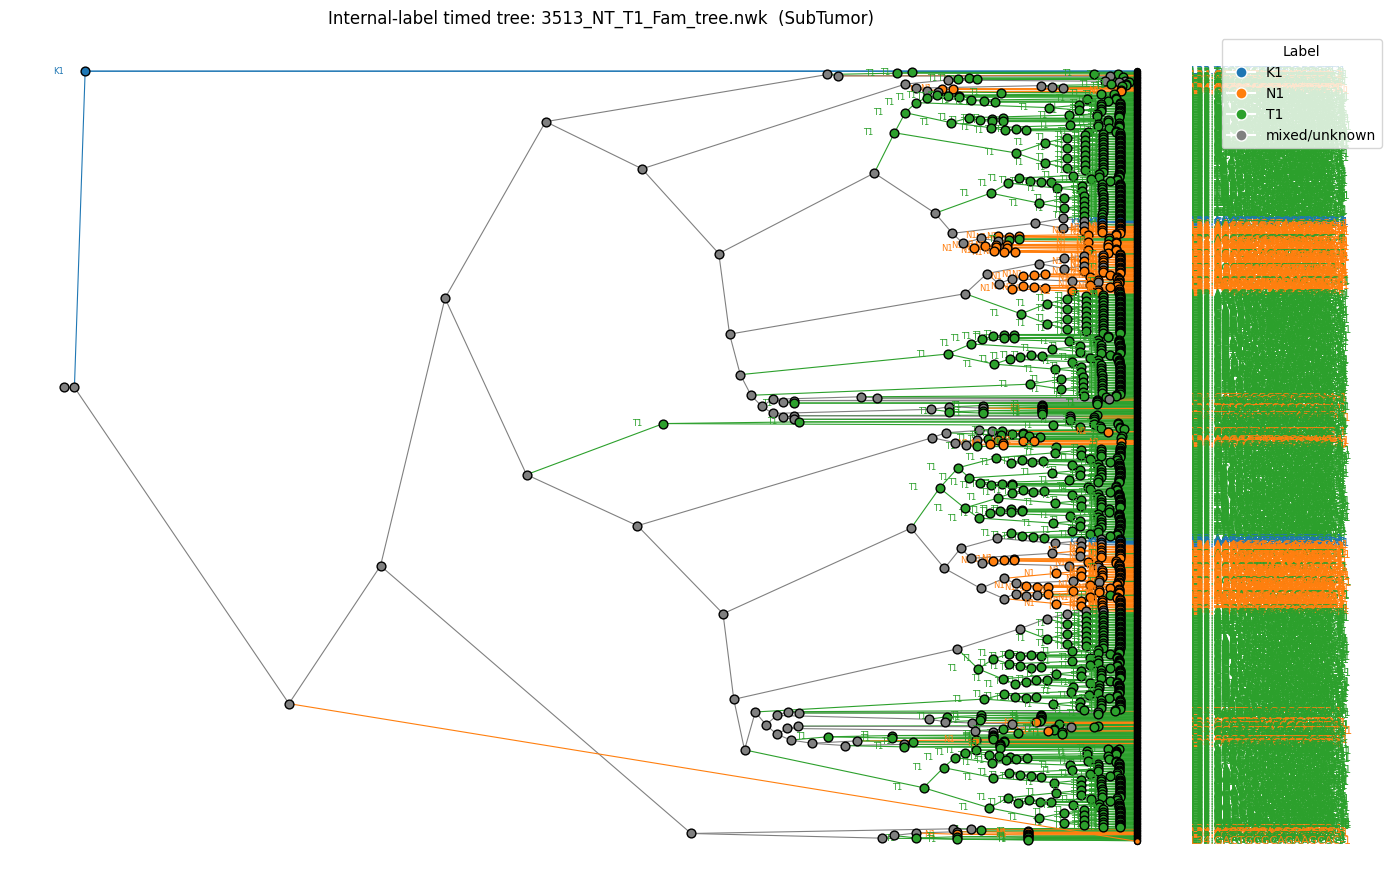

In [35]:
def infer_internal_node_labels(node, leaf_annotation, labels=None):
    if labels is None:
        labels = {}
    if not node.descendants:
        labels[node] = leaf_annotation.get(node.name, 'Unknown')
        return labels[node]

    child_labels = [infer_internal_node_labels(child, leaf_annotation, labels) for child in node.descendants]
    common_label = child_labels[0]
    if common_label is not None and common_label != 'Unknown' and all(cl == common_label for cl in child_labels):
        labels[node] = common_label
    else:
        labels[node] = None
    return labels[node]

def plot_timed_tree_with_internals(tree, leaf_annotation, title=None, figsize=(14, 9), label_fontsize=8):
    leaf_nodes = [node for node in tree.walk() if not node.descendants]
    leaf_count = len(leaf_nodes)
    leaf_y = iter(np.arange(leaf_count)[::-1])
    positions = {}
    timed_tree_layout(tree, parent_x=0.0, leaf_y=leaf_y, positions=positions)

    node_labels = {}
    infer_internal_node_labels(tree, leaf_annotation, node_labels)

    site_names = sorted({label for label in leaf_annotation.values() if label != 'Unknown'})
    palette = sns.color_palette(COLOR_PALETTE, n_colors=max(2, len(site_names)))
    color_map = {site: palette[i % len(palette)] for i, site in enumerate(site_names)}

    fig, ax = plt.subplots(figsize=figsize)
    for node_id, info in positions.items():
        node = info['node']
        if node.descendants:
            for child in node.descendants:
                child_id = next((key for key, child_info in positions.items() if child_info['node'] is child), None)
                if child_id is None:
                    continue
                x0, y0 = positions[node_id]['x'], positions[node_id]['y']
                x1, y1 = positions[child_id]['x'], positions[child_id]['y']
                child_label = node_labels.get(child)
                edge_color = color_map.get(child_label, 'gray')
                ax.plot([x0, x1], [y0, y1], color=edge_color, linewidth=0.8)

    for node_id, info in positions.items():
        node = info['node']
        node_label = node_labels.get(node)
        node_color = color_map.get(node_label, 'gray')
        size = 40 if node.descendants else 18
        ax.scatter(info['x'], info['y'], s=size, color=node_color, edgecolors='black', zorder=3)
        if node.descendants and node_label is not None:
            ax.text(info['x'] - 0.02, info['y'], node_label, fontsize=max(label_fontsize - 2, 6), color=node_color, verticalalignment='center', horizontalalignment='right')

    for node in leaf_nodes:
        nid = next(key for key, info in positions.items() if info['node'] is node)
        info = positions[nid]
        leaf_name = node.name
        site = leaf_annotation.get(leaf_name, 'Unknown')
        label_color = color_map.get(site, 'gray')
        ax.text(info['x'] + 0.05, info['y'], leaf_name, fontsize=label_fontsize, color=label_color, verticalalignment='center')

    legend_elements = [Line2D([0], [0], marker='o', color='w', label=site, markerfacecolor=color_map[site], markersize=8) for site in site_names]
    legend_elements.append(Line2D([0], [0], marker='o', color='w', label='mixed/unknown', markerfacecolor='gray', markersize=8))
    ax.legend(handles=legend_elements, title='Label', bbox_to_anchor=(1.02, 1), loc='upper left')
    ax.axis('off')
    ax.set_title(title or f'Internal-label timed tree: {TREE_NAME}  ({ANNOTATION_COLUMN})')
    plt.tight_layout()
    return fig

# Use the timed tree produced earlier. If the variable isn't available, load the saved timed tree file.
try:
    timed_tree
except NameError:
    if 'TIMED_TREE_PATH' in globals():
        timed_tree = loads(open(TIMED_TREE_PATH).read().strip())[0]
    elif 'result' in globals():
        timed_tree = loads(result['tree_newick'])[0]
    else:
        raise RuntimeError('Timed tree is not available in the current notebook state.')

fig = plot_timed_tree_with_internals(timed_tree, leaf_annotation)
plt.show()


In [36]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [37]:
import sys
sys.path.append("../src")

In [38]:
# Multiple diff-times style parameter estimation adapted for KPTracer timed tree
import networkx as nx
import numpy as np
import pandas as pd
from collections import defaultdict
from likelihood import add_node_times, assign_states_to_internal_nodes, calculate_log_likelihood_graph_diff_opt, calculate_log_likelihood_graph_diff_opt2

In [39]:
# Convert newick timed_tree to networkx DiGraph
def newick_to_nx(tree):
    G = nx.DiGraph()
    node_ids = {}
    counter = [1]
    def traverse(node, parent_id=0):
        nid = counter[0]
        counter[0] += 1
        node_ids[node] = nid
        attrs = {'name': node.name, 'dist': float(node.length) if node.length is not None else 0.0, 'is_leaf': not bool(node.descendants)}
        G.add_node(nid, **attrs)
        if parent_id is None:
            parent_id = 0
        if parent_id is not None:
            G.add_edge(parent_id, nid, length=float(node.length) if node.length is not None else 0.0)
        for child in node.descendants:
            traverse(child, nid)
    G.add_node(0, name='root', dist=0.0, is_leaf=False)
    traverse(tree, 0)
    G.graph['root'] = 0
    return G

In [40]:
# Convert timed_tree to networkx and add node times

def collapse_unary_nodes(G):
    while True:
        unary = [n for n in G.nodes if n != G.graph.get('root') and G.in_degree(n) == 1 and G.out_degree(n) == 1]
        if not unary:
            break
        n = unary[0]
        parent = next(G.predecessors(n))
        child = next(G.successors(n))
        length = G[parent][n]['length'] + G[n][child]['length']
        G.add_edge(parent, child, length=length)
        G.remove_node(n)
    return G

In [41]:
# Load timed_tree if not in memory
try:
    timed_tree
except NameError:
    if 'TIMED_TREE_PATH' in globals():
        timed_tree = loads(open(TIMED_TREE_PATH).read().strip())[0]
    elif 'result' in globals():
        timed_tree = loads(result['tree_newick'])[0]
    else:
        raise RuntimeError('Timed tree not available')

leaf_sites = sorted({v for v in leaf_annotation.values() if v != 'Unknown'})
print('Found site labels:', leaf_sites)


Found site labels: ['K1', 'N1', 'T1']


In [42]:
T = newick_to_nx(timed_tree)
T = add_node_times(T, root=T.graph['root'])
T = collapse_unary_nodes(T)
# Assign observed leaf states from leaf_annotation
for n, d in list(T.nodes(data=True)):
    if T.out_degree(n) == 0:
        lbl = d.get('name')
        if lbl is not None and str(lbl) in leaf_annotation:
            T.nodes[n]['state'] = leaf_annotation.get(str(lbl), '?')
        else:
            T.nodes[n]['state'] = '?'

In [43]:
# ## move nodes up
# EPS = 1e-4
# T.nodes[37]['T'] = T.nodes[29]['T'] - EPS
# T.nodes[38]['T'] = T.nodes[37]['T'] - EPS
# T.nodes[41]['T'] = T.nodes[37]['T'] - EPS

# T.nodes[1622]['T'] = T.nodes[1590]['T'] - EPS
# T.nodes[1623]['T'] = T.nodes[1622]['T'] - EPS
# T.nodes[1624]['T'] = T.nodes[1623]['T'] - EPS

# T.nodes[1496]['T'] = T.nodes[1495]['T'] - EPS
# T.nodes[1497]['T'] = T.nodes[1496]['T'] - EPS
# T.nodes[1498]['T'] = T.nodes[1497]['T'] - EPS

# li = [(1037, 1045), (1045, 1049)] + [(20, 22)] + [(631, 632), (623, 631), (622, 623), (590, 622)] + \
# [(1719, 1720) , (1720, 1721), (1721, 1729), (1721, 1722)] + [(1526, 1543), (1527, 1543),(1543, 1544)] + \
# [(590, 591), (591, 592), (592, 593)] + [(461, 493), (493, 494), (494, 495)]

# for u, v in li:
#     T.nodes[v]['T'] = T.nodes[u]['T'] + EPS

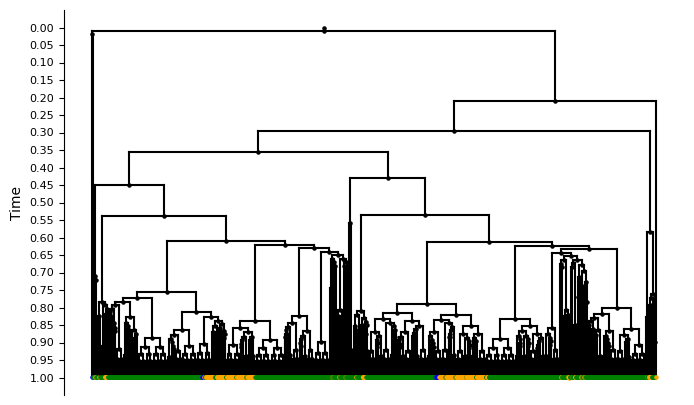

In [44]:
from plotters import draw_ultrametric_tree

draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False)
                    #   , red_edges=[(29, 37), (37, 38), (38, 39)] + li)

In [45]:
from dataprocessor import export_tree

In [46]:
state_dict = {
    'T1': 0,
    'N1': 1,
    'K1': 2,
}

for n, d in T.nodes(data=True):
    state = d.get('state')
    if state is not None and state in state_dict:
        T.nodes[n]['state'] = state_dict[state]
    else:
        T.nodes[n]['state'] = -1  # Unknown or unassigned

In [47]:
export_tree(T, f"../data/KPTracer-Data/processed_data/nodes.csv", f"../data/KPTracer-Data/processed_data/edges.csv")

In [97]:
diff_T = nx.DiGraph()

diff_T.add_node('T0', diff_time=0.97)
diff_T.add_node('N0', diff_time=0.99)

diff_T.add_node('T1', diff_time=1)
diff_T.add_node('N1', diff_time=1)
diff_T.add_node('K1', diff_time=1)

diff_T.add_edge('T0', 'T1')
diff_T.add_edge('T0', 'N0')
diff_T.add_edge('N0', 'N1')
diff_T.add_edge('N0', 'K1')

/Users/samin/workspace/phylodynamic-carta/notebooks/../src/plotters.py:245: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


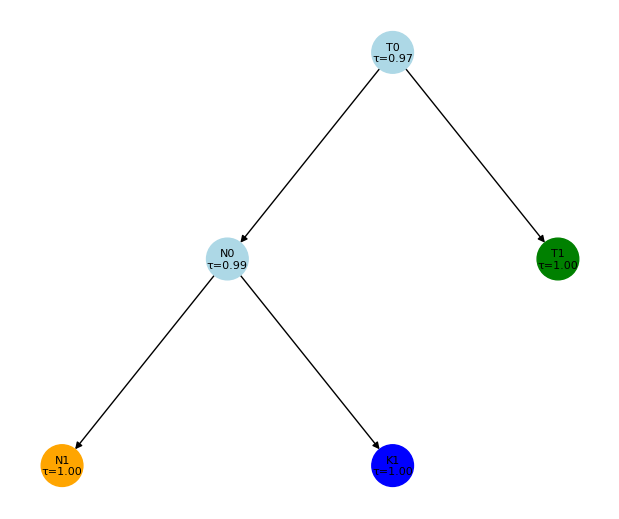

In [98]:
from plotters import plot_differentiation_tree
plot_differentiation_tree(diff_T)

In [99]:
rev_diff_T = diff_T.copy()

for n in rev_diff_T.nodes:
    rev_diff_T.nodes[n]['diff_time'] = 1 - rev_diff_T.nodes[n]['diff_time']

In [100]:
rev_diff_T.nodes(data=True)

NodeDataView({'T0': {'diff_time': 0.030000000000000027}, 'N0': {'diff_time': 0.010000000000000009}, 'T1': {'diff_time': 0}, 'N1': {'diff_time': 0}, 'K1': {'diff_time': 0}})

In [101]:
# Parameter search functions (from explore-tls-data-2.ipynb)
from scipy.optimize import minimize
from scipy.special import expit as sigmoid
types = list(rev_diff_T.nodes())
transition_maps = [(i, list(rev_diff_T.successors(i))) for i in rev_diff_T.nodes() if len(list(rev_diff_T.successors(i)))>0]

print('Types:', types)
print('Transition maps:', transition_maps)

Types: ['T0', 'N0', 'T1', 'N1', 'K1']
Transition maps: [('T0', ['T1', 'N0']), ('N0', ['N1', 'K1'])]


In [102]:
# Assign internal node states using diff_T
# T = assign_states_to_internal_nodes(T, diff_T, correct=True)
trees = [T]


MAX_DEATH = 1.0
MAX_BIRTH = 25.0


def unpack_params(theta):
    k = 0
    death = {}
    for t in types:
        death[t] = MAX_DEATH * sigmoid(theta[k])
    k += 1
    birth = {}
    for t in types:
        birth[t] = death[t] + (MAX_BIRTH - death[t]) * sigmoid(theta[k])
    k += 1
    Q = pd.DataFrame(0.0, index=types, columns=types)
    for i, transition_to in transition_maps:
        logits = []
        js = []
        for j in transition_to:
            logits.append(theta[k])
            js.append(j)
            k += 1
        logits = np.array(logits)
        logits -= np.max(logits)
        exp_logits = np.exp(logits)
        probs = exp_logits / exp_logits.sum()
        for idx, j in enumerate(js):
            Q.loc[i, j] = probs[idx]
    return birth, death, Q

def neg_log_likelihood(theta, trees, diff_T, sampling_rate=1.0):
    birth, death, Q = unpack_params(theta)
    total_nll = 0.0
    for cell_lineage_T in trees:
        try:
            l, _, _ = calculate_log_likelihood_graph_diff_opt2(
                T=cell_lineage_T,
                birth_rates=birth,
                death_rates=death,
                sampling_rate=sampling_rate,
                transition_probabilities=Q,
                diff_T=diff_T
            )
        except Exception as e:
            l = -1e80
        total_nll += -l
    return total_nll

def pack_initial():
    params = []
    params.append(0.0)
    params.append(0.0)
    
    for i, transition_to in transition_maps:
        for j in transition_to:
            params.append(0.0)
    return np.array(params)

def find_params(trees, diff_T):
    theta0 = pack_initial()
    result = minimize(
        neg_log_likelihood,
        theta0,
        args=(trees, diff_T, 0.5),
        method="L-BFGS-B"
    )
    print(result)
    return result

print('Starting parameter search for KPTracer timed tree...')
res = find_params(trees, rev_diff_T)
print('Done. Optimizer status:', getattr(res, 'success', None), getattr(res, 'message', None))


Starting parameter search for KPTracer timed tree...
  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: -1292.1265456366616
        x: [ 1.136e+01  6.389e-01  6.305e-01 -6.309e-01  1.392e+00
            -1.393e+00]
      nit: 28
      jac: [-4.547e-05 -4.502e-02 -3.083e-02  3.079e-02  6.071e-03
            -6.071e-03]
     nfev: 217
     njev: 31
 hess_inv: <6x6 LbfgsInvHessProduct with dtype=float64>
Done. Optimizer status: True CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH


In [103]:
birth_rates, death_rates, Q = unpack_params(res.x)
birth_rates, death_rates, Q

({'T0': np.float64(16.708219721252505),
  'N0': np.float64(16.708219721252505),
  'T1': np.float64(16.708219721252505),
  'N1': np.float64(16.708219721252505),
  'K1': np.float64(16.708219721252505)},
 {'T0': np.float64(0.9999883785242992),
  'N0': np.float64(0.9999883785242992),
  'T1': np.float64(0.9999883785242992),
  'N1': np.float64(0.9999883785242992),
  'K1': np.float64(0.9999883785242992)},
      T0        N0        T1        N1        K1
 T0  0.0  0.220737  0.779263  0.000000  0.000000
 N0  0.0  0.000000  0.000000  0.941884  0.058116
 T1  0.0  0.000000  0.000000  0.000000  0.000000
 N1  0.0  0.000000  0.000000  0.000000  0.000000
 K1  0.0  0.000000  0.000000  0.000000  0.000000)

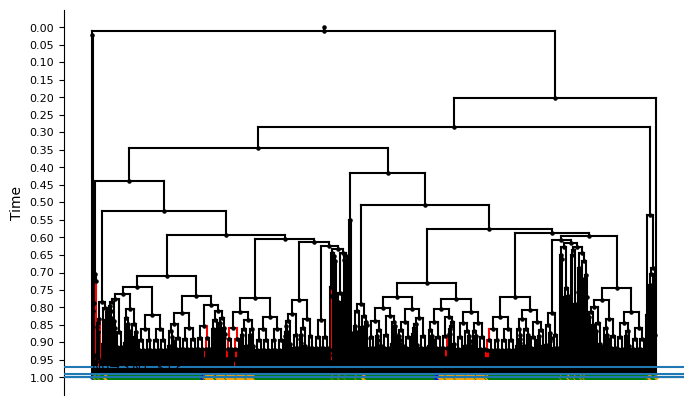

In [104]:
draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False, diff_T=diff_T, red_edges=[(29, 37), (37, 38), (38, 39)] + li)

In [105]:
from likelihood import calculate_log_likelihood_graph_diff

In [106]:
l, LL, U = calculate_log_likelihood_graph_diff(
    T=T,
    birth_rates=birth_rates,
    death_rates=death_rates,
    sampling_rate=0.5,
    transition_probabilities=Q,
    diff_T=rev_diff_T
)
l

(38 → 39) @ 0.1663829313741001 | state T0 | diff_time 0.030000000000000027 | v_t 4.5494719103089665e-12
incorrect
(38 → 39) @ 0.030000000000000027 | state T1 | diff_time 0 | v_t 4.5494719103089665e-12
(38 → 39) @ 0.030000000000000027 | state N0 | diff_time 0.010000000000000009 | v_t 4.5494719103089665e-12
incorrect
(38 → 39) @ 0.010000000000000009 | state N1 | diff_time 0 | v_t 4.5494719103089665e-12
(38 → 39) @ 0.010000000000000009 | state K1 | diff_time 0 | v_t 4.5494719103089665e-12
(38 → 39) @ 0.1663829313741001 | state N0 | diff_time 0.010000000000000009 | v_t 4.5494719103089665e-12
incorrect
(38 → 39) @ 0.1663829313741001 | state T1 | diff_time 0 | v_t 4.5494719103089665e-12
(38 → 39) @ 0.1663829313741001 | state N1 | diff_time 0 | v_t 4.5494719103089665e-12
(38 → 39) @ 0.1663829313741001 | state K1 | diff_time 0 | v_t 4.5494719103089665e-12


1292.1265456366616

In [107]:
max_LL = defaultdict(lambda: float('-inf'))

for (u, v, t, state), val in LL.items():
    key = (u, v)
    max_LL[key] = max(max_LL[key], val)

max_LL = dict(max_LL)

max_LL

{(3, 4): -0.7092641198998492,
 (3, 5): -0.7092641198998492,
 (12, 13): -0.7774010805620754,
 (12, 14): -0.7774010805600442,
 (17, 18): -0.7748761194633504,
 (17, 19): -0.7748761194633504,
 (15, 16): -0.7774010805315893,
 (15, 17): 1.2636235971845433,
 (11, 12): -2.500812808957673,
 (11, 15): 1.0429709216033105,
 (24, 25): -0.7483141613262961,
 (24, 26): -0.7483141613262961,
 (22, 23): -0.7092641198949565,
 (22, 24): 1.2901855553215975,
 (20, 21): -0.7092641198701425,
 (20, 22): -4.530802088297716,
 (10, 11): 0.09984189877280825,
 (10, 20): -7.3686438873341595,
 (31, 32): -0.7774010805568157,
 (31, 33): -0.7774010805568157,
 (34, 35): -0.7774010805591093,
 (34, 36): -0.7774010805620754,
 (30, 31): -1.0693130117958827,
 (30, 34): -0.8706993039657589,
 (38, 39): -0.7092641198952991,
 (38, 40): -0.777401080557526,
 (43, 44): -0.7170884651741484,
 (43, 45): -0.7170884651741484,
 (41, 42): -0.7092641198858362,
 (41, 43): 1.3214112514737448,
 (37, 38): -3.3433010435465524,
 (37, 41): -1.24448

In [108]:
bad_keys = [k for k, v in max_LL.items() if v == float('-inf')]

print(bad_keys)

[]


In [85]:
for k, v in LL.items():
    # if k[0] == 336 and k[1] == 346:
    # if k[0] == 336 and k[1] == 346 and k[3].startswith("MP"):
    if k[0] == 1729 and k[1] == 1730:
        print(k, v)

(1729, 1730, 0.050000000000000044, 'T1') -inf
(1729, 1730, 0.050000000000000044, 'N0') 1.0445945230506808
(1729, 1730, 0.13796460310489944, 'T0') -1.366008097686859
(1729, 1730, 0.13796460310489944, 'N0') 0.1455911843263289
(1729, 1730, 0.13796460310489944, 'T1') -inf
(1729, 1730, 0.13796460310489944, 'N1') 0.2653587559008139
(1729, 1730, 0.13796460310489944, 'K1') -inf


In [86]:
[(461, 493), (493, 494), (494, 495)]

[(461, 493), (493, 494), (494, 495)]

In [71]:
node = 1631
print(T.nodes[node])

print(list(T.successors(node)))
print(list(T.predecessors(node)))

{'name': None, 'dist': 0.032795589135919734, 'is_leaf': False, 'T': 0.056429812032059656}
[1632, 1635]
[1623]


In [72]:
U

{('T0', 0): 0.5,
 ('N0', 0): 0.5,
 ('T1', 0): 0.5,
 ('N1', 0): 0.5,
 ('K1', 0): 0.5,
 ('N0', 0.010000000000000009): np.float64(0.46348772128734717),
 ('T0', 0.05500000000000005): np.float64(0.3142829555998039)}